# Load initial

In [2]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
GTE_DIR=os.environ["GTE_DIR"]
from glaciation_time_estimator.auxiliary_func.config_reader import read_config
from glaciation_time_estimator.auxiliary_func.Helper_fun import float_range
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import cmcrameri.cm
from glaciation_time_estimator.auxiliary_func.chunking_data import ChunkLoader
import datetime as dt

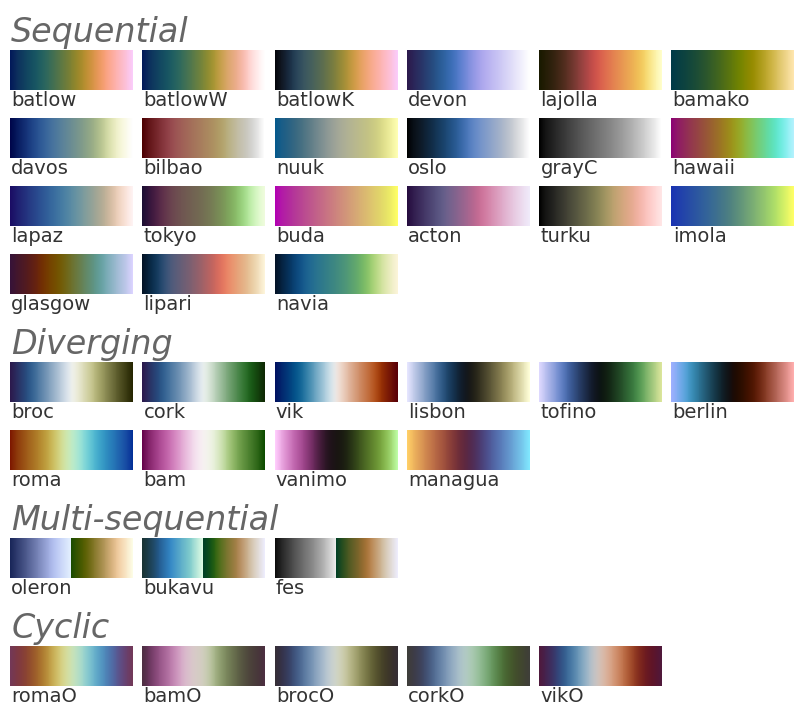

In [3]:
cmcrameri.cm.show_cmaps()

In [4]:
colormap = cmcrameri.cm.lipariS

In [5]:
color_low_res = colormap(0)
color_high_res = colormap(4)
color_model_old_wbf = colormap(3)
color_model_new_wbf = colormap(2)

In [6]:
glac_threshold=0.4
def calculate_pole_temp_occurance_rate(dfs):
    cloud_chunk , _ , _ = dfs
    return pd.pivot_table(cloud_chunk,values='is_glaciating' ,index=["Hemisphere"], columns=["min_temp"], aggfunc='mean')
def calculate_pole_temp_occurance_rate_glac_possible(dfs):
    cloud_chunk , _ , _ = dfs
    return pd.pivot_table(cloud_chunk[cloud_chunk.max_water_frac > glac_threshold],values='is_glaciating' ,index=["Hemisphere"], columns=["min_temp"], aggfunc='mean')


# 1 Load data

CLAAS data (1 degree)

In [7]:
# glac_low_res_01 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_Glaciations_20080901.0000_20080914.2345.parquet")
# glac_low_res_02 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_Glaciations_20080915.0000_20080930.2345.parquet")
# glac_low_res = pd.concat([glac_low_res_01,glac_low_res_02],axis=0,ignore_index=True)
# clouds_low_res_01 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_clouds_20080901.0000_20080914.2345.parquet")
# clouds_low_res_02 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_clouds_20080915.0000_20080930.2345.parquet")
# clouds_low_res = pd.concat([clouds_low_res_01,clouds_low_res_02],axis=0,ignore_index=True)


CLAAS data (original - 0.15)

In [8]:
config_claas_low_res = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/Low_resolution_tests/Agg_30/config_n2o.yaml")
loader_claas_low_res = ChunkLoader([2007],config_claas_low_res,filter=True)

Cloud_fps: {2007: '/wolke_scratch/dnikolo/GTE_Results/Low_resolution/Final_results/2007_all.parquet'}


In [9]:
config_claas_high_res = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/config_n2o.yaml")
loader_claas_high_res = ChunkLoader([2007],config_claas_high_res,filter=True)

Cloud_fps: {2007: '/wolke_scratch/dnikolo/GTE_Results/Final_results/2007_all.parquet'}


In [10]:
config_icon = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/ICON_output/wbf_v1_ndg_1y/read_n2o.yaml")
loader_icon = ChunkLoader([2007],config_icon,filter=True)

Cloud_fps: {2007: '/wolke_scratch/dnikolo/ICON_Data/wbf_v1_ndg_1y/postprocessing_output/Final_results/2007_all.parquet'}


In [11]:
config_icon_new_wbf = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/ICON_output/wbf_v3_ndg_1y/read_n2o.yaml")
loader_icon_new_wbf = ChunkLoader([2007],config_icon_new_wbf,filter=True)

Cloud_fps: {2007: '/wolke_scratch/dnikolo/ICON_Data/wbf_v3_ndg_1y/postprocessing_output/Final_results/2007_all.parquet'}


In [16]:
clouds_model_new_wbf

,tracknumber,is_large_pix_cloud,is_cot_valid_cloud,is_ctp_valid_cloud,is_liq,is_mix,is_ice,max_water_frac,max_ice_fraction,avg_size[km],...,pole,Hemisphere,Lifetime [h],Radius [km],Level,Optical Thickness,Cloud type,Season,month,is_glaciating
0,1.0,False,False,False,True,False,False,0.999998,0.053561,626489.319643,...,np,North,8.50,446.562139,NaN,Thin,None,DJF,1.0,False
3,4.0,False,False,False,True,False,False,1.000000,0.028828,140031.320265,...,np,North,20.50,211.124024,NaN,Thin,None,DJF,1.0,False
4,5.0,False,False,False,True,False,False,1.000000,0.000699,139513.549006,...,np,North,5.25,210.733343,NaN,Thin,None,DJF,1.0,False
5,6.0,False,False,False,True,False,False,1.000000,0.000063,153892.654688,...,np,North,1.00,221.326802,NaN,Thin,None,DJF,1.0,False
6,7.0,False,False,False,True,False,False,1.000000,0.028585,106622.042550,...,np,North,6.75,184.224999,NaN,Thin,None,DJF,1.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2100758,6121.0,False,False,False,False,False,True,0.000167,0.999923,24198.138672,...,sp,South,0.75,87.763926,NaN,Thin,None,DJF,12.0,False
2100759,6122.0,False,False,False,False,True,False,0.769575,0.343221,27225.009766,...,sp,South,1.50,93.091298,NaN,Thin,None,DJF,12.0,False
2100764,6127.0,False,False,False,False,False,True,0.004473,1.000000,47945.878906,...,sp,South,0.75,123.538040,NaN,Thin,None,DJF,12.0,False
2100765,6128.0,False,False,False,False,False,True,0.027813,1.000000,39119.970703,...,sp,South,0.75,111.589755,NaN,Thin,None,DJF,12.0,False


In [22]:
clouds_model.sample(10000,random_state=1).equals(clouds_model_new_wbf.sample(10000,random_state=1))

True

Model 160 km

In [ ]:
clouds_model = loader_icon.cloud_chunk
glac_model = loader_icon.glac_chunk
clouds_high_res = loader_claas_high_res.cloud_chunk
glac_high_res = loader_claas_high_res.glac_chunk
clouds_low_res = loader_claas_low_res.cloud_chunk
glac_low_res = loader_claas_low_res.glac_chunk
clouds_model_new_wbf = loader_icon_new_wbf.cloud_chunk
glac_model_new_wbf = loader_icon_new_wbf.glac_chunk

In [13]:
start_time=pd.Timestamp("2008-09-01")
end_time= pd.Timestamp("2008-09-08")
def time_filter(df):
    return df[(df.track_start_time>=start_time) & (df.track_start_time<end_time)]
def get_peak_if(glac_df_row):
    return glac_df_row["ice_frac_hist"][glac_df_row["Glac_peak_ind"]]
def set_peak_if(glac_df):
    glac_df["Peak IF"] = glac_df.apply(get_peak_if,axis=1)
def filter_df(df):
    return df[(~df.is_large_pix_cloud) & (abs(df.avg_lat)>30)]
def preproc_glac(glac_df):
    set_peak_if(glac_df)
    return filter_df(time_filter(glac_df))
def preproc_cloud(cloud_df):
    return filter_df(time_filter(cloud_df))

set_peak_if(glac_high_res)
set_peak_if(glac_low_res)
set_peak_if(glac_model)
set_peak_if(glac_model_new_wbf)

# clouds_high_res = clouds_high_res[clouds_high_res["avg_size[km]"]>3e4]

In [14]:
# def set_is_glaciating(cloud_df,glac_df):
#     cloud_df['is_glaciating'] = (
#                     cloud_df.index.isin(
#                         glac_df['Cloud_ID']
#                     )
#                 )

# set_is_glaciating(clouds_low_res,glac_low_res)
# set_is_glaciating(clouds_model_offline,glac_model_offline)
# set_is_glaciating(clouds_model,glac_model)


In [15]:
# def set_hemisphere(cloud_df):
#     cloud_df['Hemisphere'] = np.where(cloud_df['avg_lat']>=0,'North','South')
# set_hemisphere(clouds_model_offline)
# set_hemisphere(clouds_model)

# Plots

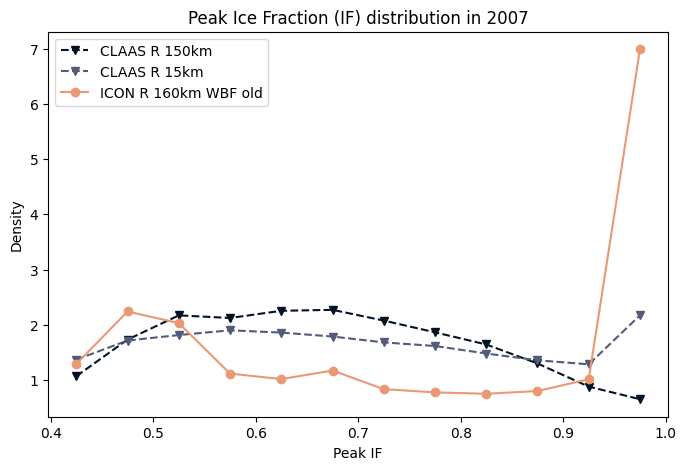

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

bins = 12

# CLAAS
counts1, edges1 = np.histogram(glac_low_res["Peak IF"].dropna(), bins=bins, range =[0.4,1], density=True)
centers1 = 0.5 * (edges1[:-1] + edges1[1:])
ax.plot(centers1, counts1, "--v", label="CLAAS R 150km", color=color_low_res)

# GLAC High Res
counts3, edges3 = np.histogram(glac_high_res["Peak IF"].dropna(), bins=bins, range =[0.4,1], density=True)
centers3 = 0.5 * (edges3[:-1] + edges3[1:])
ax.plot(centers3, counts3, "--v", label="CLAAS R 15km", color=color_high_res)

# ICON
counts2, edges2 = np.histogram(glac_model["Peak IF"].dropna(), bins=bins, range =[0.4,1], density=True)
centers2 = 0.5 * (edges2[:-1] + edges2[1:])
ax.plot(centers2, counts2, "-o", label="ICON R 160km WBF old", color=color_model_old_wbf)

# ICON new WBF
counts4, edges4 = np.histogram(glac_model_new_wbf["Peak IF"].
dropna(), bins=bins, range =[0.4,1], density=True)
centers4 = 0.5 * (edges4[:-1] + edges4[1:])
ax.plot(centers4, counts4, "-o", label="ICON R 160km WBF new", color=color_model_new_wbf)


ax.set_title("Peak Ice Fraction (IF) distribution in 2007")
ax.set_xlabel("Peak IF")
ax.set_ylabel("Density")
ax.legend()

cmcrameri

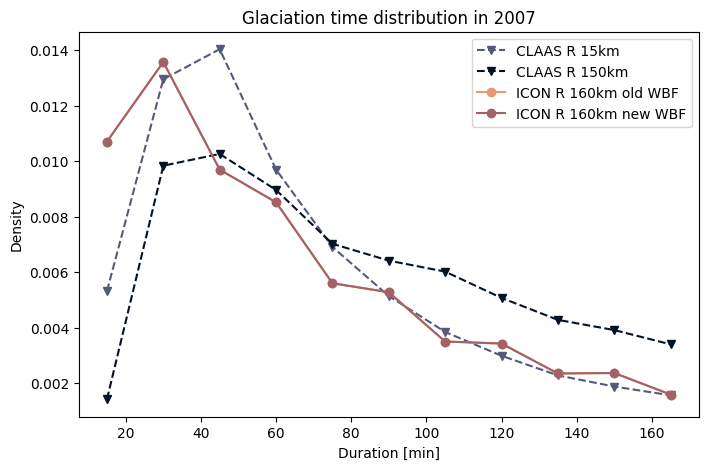

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))

bins = np.arange(7.5, 181, 15)

# CLAAS R 15km
counts0, edges0 = np.histogram(
    glac_high_res["Time [m]"].dropna(),
    bins=bins,
    density=True
)
centers0 = 0.5 * (edges0[:-1] + edges0[1:])
ax.plot(centers0, counts0, "--v", label="CLAAS R 15km", color=color_high_res)

# CLAAS R 150km
counts1, edges1 = np.histogram(
    glac_low_res["Time [m]"].dropna(),
    bins=bins,
    density=True
)
centers1 = 0.5 * (edges1[:-1] + edges1[1:])
ax.plot(centers1, counts1, "--v", label="CLAAS R 150km", color=color_low_res)
# ICON R 160km
counts2, edges2 = np.histogram(
    glac_model["Time [m]"].dropna(),
    bins=bins,
    density=True
)
centers2 = 0.5 * (edges2[:-1] + edges2[1:])
ax.plot(centers2, counts2, "-o", label="ICON R 160km old WBF", color=color_model_old_wbf)

# ICON R 160km WBF v2
counts3, edges3 = np.histogram(
    glac_model_new_wbf["Time [m]"].dropna(),
    bins=bins,
    density=True
)
centers3 = 0.5 * (edges3[:-1] + edges3[1:])
ax.plot(centers3, counts3, "-o", label="ICON R 160km new WBF", color=color_model_new_wbf)

ax.set_title("Glaciation time distribution in 2007")
ax.set_xlabel("Duration [min]")
ax.set_ylabel("Density")
ax.legend()
plt.show()

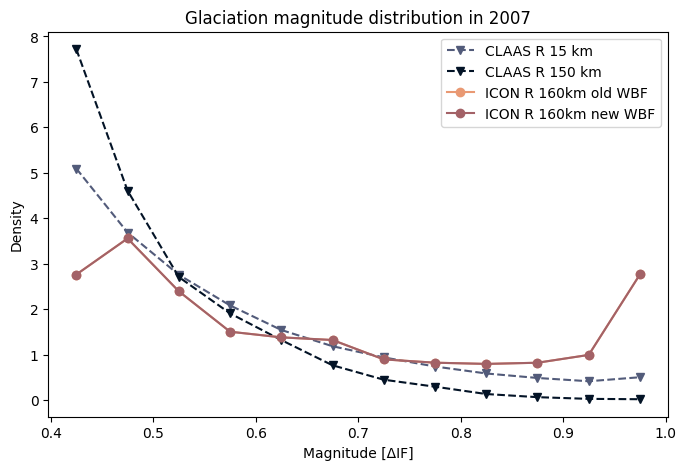

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))

bins = np.linspace(0.4, 1.0, 13)  # 12 bins from 0.4 to 1.0

# CLAAS R 15km
counts0, edges0 = np.histogram(
    glac_high_res["Magnitude"].dropna(),
    bins=bins,
    density=True
)
centers0 = 0.5 * (edges0[:-1] + edges0[1:])
ax.plot(centers0, counts0, "--v", label="CLAAS R 15 km", color=color_high_res)

# CLAAS R 150km
counts1, edges1 = np.histogram(
    glac_low_res["Magnitude"].dropna(),
    bins=bins,
    density=True
)
centers1 = 0.5 * (edges1[:-1] + edges1[1:])
ax.plot(centers1, counts1, "--v", label="CLAAS R 150 km", color=color_low_res)

# ICON R 160km old WBF
counts2, edges2 = np.histogram(
    glac_model["Magnitude"].dropna(),
    bins=bins,
    density=True
)
centers2 = 0.5 * (edges2[:-1] + edges2[1:])
ax.plot(centers2, counts2, "-o", label="ICON R 160km old WBF", color=color_model_old_wbf)

# ICON R 160km new WBF
counts3, edges3 = np.histogram(
    glac_model_new_wbf["Magnitude"].dropna(),
    bins=bins,
    density=True
)
centers3 = 0.5 * (edges3[:-1] + edges3[1:])
ax.plot(centers3, counts3, "-o", label="ICON R 160km new WBF", color=color_model_new_wbf)

ax.set_title("Glaciation magnitude distribution in 2007")
ax.set_xlabel("Magnitude [ΔIF]")
ax.set_ylabel("Density")
ax.legend()

plt.show()

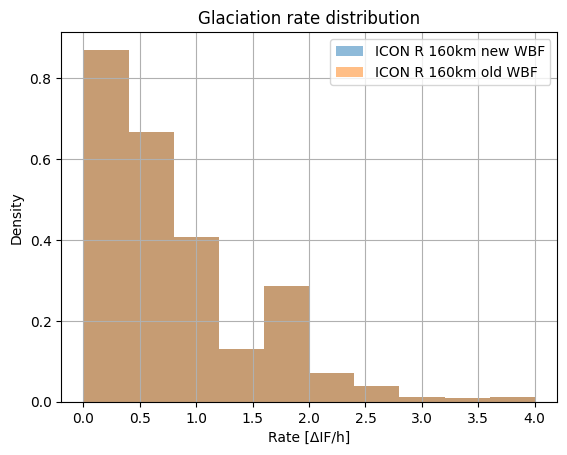

In [17]:
# (glac_low_res["Magnitude"]/(glac_low_res["Time [m]"]/60)).hist( alpha=0.5, density=True,label="CLAAS R 150km")
# glac_model_offline["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON R 160km")
# (glac_model_offline["Magnitude"]/(glac_model_offline["Time [m]"]/15)).hist( alpha=0.5, density=True,label="ICON Old WBF R 160km")
(glac_model_new_wbf["Magnitude"]/(glac_model_new_wbf["Time [m]"]/60)).hist( alpha=0.5, density=True,label="ICON R 160km new WBF")
(glac_model["Magnitude"]/(glac_model["Time [m]"]/60)).hist( alpha=0.5, density=True,label="ICON R 160km old WBF")

plt.title("Glaciation rate distribution")
plt.xlabel("Rate [ΔIF/h]")
plt.ylabel("Density")
plt.legend()


In [18]:
print(glac_low_res.track_length.median())
print(glac_low_res["Time [m]"].median())
print(glac_low_res["Time [m]"].std())

0 days 03:30:00
105.0
139.87547316345405


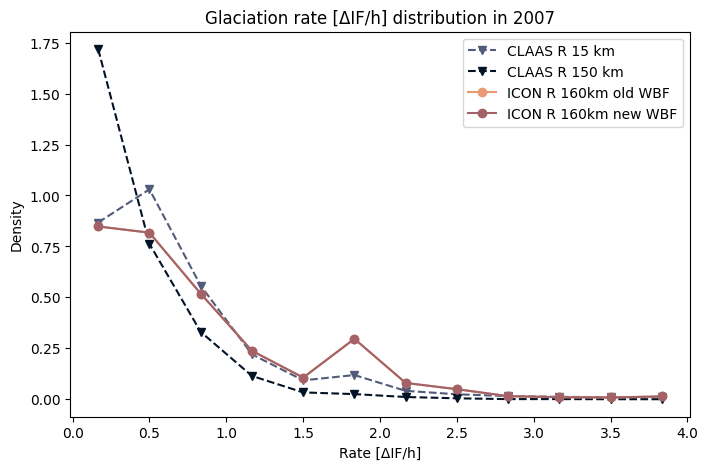

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))

# Adjust bin range if needed after seeing your data
bins = np.linspace(0, 4.0, 13)  # 12 bins

# CLAAS R 15 km
rate0 = glac_high_res["Magnitude"] / (glac_high_res["Time [m]"] / 60)
counts0, edges0 = np.histogram(
    rate0.dropna(),
    bins=bins,
    density=True
)
centers0 = 0.5 * (edges0[:-1] + edges0[1:])
ax.plot(centers0, counts0, "--v", label="CLAAS R 15 km", color=color_high_res)

# CLAAS R 150 km
rate1 = glac_low_res["Magnitude"] / (glac_low_res["Time [m]"] / 60)
counts1, edges1 = np.histogram(
    rate1.dropna(),
    bins=bins,
    density=True
)
centers1 = 0.5 * (edges1[:-1] + edges1[1:])
ax.plot(centers1, counts1, "--v", label="CLAAS R 150 km", color=color_low_res)

# ICON R 160km old WBF
rate2 = glac_model["Magnitude"] / (glac_model["Time [m]"] / 60)
counts2, edges2 = np.histogram(
    rate2.dropna(),
    bins=bins,
    density=True
)
centers2 = 0.5 * (edges2[:-1] + edges2[1:])
ax.plot(centers2, counts2, "-o", label="ICON R 160km old WBF", color=color_model_old_wbf)

# ICON R 160km new WBF
rate3 = glac_model_new_wbf["Magnitude"] / (glac_model_new_wbf["Time [m]"] / 60)
counts3, edges3 = np.histogram(
    rate3.dropna(),
    bins=bins,
    density=True
)
centers3 = 0.5 * (edges3[:-1] + edges3[1:])
ax.plot(centers3, counts3, "-o", label="ICON R 160km new WBF", color=color_model_new_wbf)

ax.set_title("Glaciation rate [ΔIF/h] distribution in 2007")
ax.set_xlabel("Rate [ΔIF/h]")
ax.set_ylabel("Density")
ax.legend()

plt.show()

/tmp/ipykernel_15533/4245337185.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(['{:,.0%}'.format(x) for x in vals])


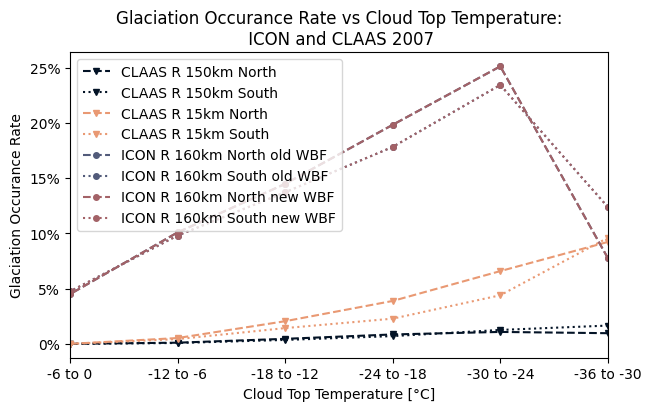

In [20]:
fig,ax = plt.subplots(1, 1, figsize=(6.4,  4), layout="constrained")
high_res_occ_rate = calculate_pole_temp_occurance_rate((clouds_high_res,None,None))
low_res_occ_rate = calculate_pole_temp_occurance_rate((clouds_low_res,None,None))
# model_occ_rate = calculate_pole_temp_occurance_rate((clouds_model_offline,None,None))
model_online_occ_rate = calculate_pole_temp_occurance_rate((clouds_model,None,None))
model_new_wbf_occ_rate = calculate_pole_temp_occurance_rate((clouds_model_new_wbf ,None,None))


ax.plot(low_res_occ_rate.columns,low_res_occ_rate.loc['North'],label='CLAAS R 150km North',color=colormap(0),linestyle='dashed',marker='v',markersize=4)
ax.plot(low_res_occ_rate.columns,low_res_occ_rate.loc['South'],label='CLAAS R 150km South',color=colormap(0),linestyle='dotted',marker='v',markersize=4)
ax.plot(high_res_occ_rate.columns,high_res_occ_rate.loc['North'],label='CLAAS R 15km North',color = colormap(3),linestyle='dashed',marker='v',markersize=4)
ax.plot(high_res_occ_rate.columns,high_res_occ_rate.loc['South'],label='CLAAS R 15km South',color = colormap(3),linestyle='dotted',marker='v',markersize=4)
# ax.plot(model_occ_rate.columns,model_occ_rate.loc['North'],label='ICON Old WBF R 160km North',color=colormap(2),linestyle='dashed',marker='v',markersize=4)
# ax.plot(model_occ_rate.columns,model_occ_rate.loc['South'],label='ICON Old WBF R 160km South',color=colormap(2),linestyle='dotted',marker='v',markersize=4)
ax.plot(model_online_occ_rate.columns,model_online_occ_rate.loc['North'],label='ICON R 160km North old WBF',color=colormap(4),linestyle='dashed',marker='o',markersize=4)
ax.plot(model_online_occ_rate.columns,model_online_occ_rate.loc['South'],label='ICON R 160km South old WBF',color=colormap(4),linestyle='dotted',marker='o',markersize=4)
ax.plot(model_new_wbf_occ_rate.columns,model_new_wbf_occ_rate.loc['North'],label='ICON R 160km North new WBF',color=colormap(2),linestyle='dashed',marker='o',markersize=4)
ax.plot(model_new_wbf_occ_rate.columns,model_new_wbf_occ_rate.loc['South'],label='ICON R 160km South new WBF',color=colormap(2),linestyle='dotted',marker='o',markersize=4)


ax.set_xlim(-36,-6)

ax.invert_xaxis()
vals = ax.get_yticks()
ax.set_yticklabels(['{:,.0%}'.format(x) for x in vals])
ax.set_ylabel('Glaciation Occurance Rate')
ax.legend(loc="upper left")
ax.set_xlabel('Cloud Top Temperature [°C]')
ax.set_xticks(np.arange(-36,-6+1,6),labels=[f"{i} to {i+6}" for i in range(-36,0,6)])
ax.set_title('Glaciation Occurance Rate vs Cloud Top Temperature:\n ICON and CLAAS 2007')
fig.savefig("/wolke_scratch/dnikolo/MSGI/figures/model_vs_CLAAS_occ_rate.png",dpi=300)

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
SEASON_ORDER = ["DJF", "MAM", "JJA", "SON"]

def get_month_mask_from_time(clouds, months, time_name="track_start_time"):
    """
    Return boolean mask selecting entries whose `time_name` month is in `months`.

    Works for xarray objects and pandas-like tables as long as
    `clouds[time_name]` exists and is datetime-like.
    """
    time = clouds[time_name]

    # xarray / numpy datetime compatible
    try:
        return time.dt.month.isin(months)
    except Exception:
        # fallback for pandas-like objects
        time = pd.to_datetime(time)
        return time.dt.month.isin(months)


def subset_clouds_by_season(clouds, season, time_name="track_start_time"):
    """
    Subset cloud dataset by meteorological season using track_start_time.
    Assumes clouds is either:
      - xarray Dataset/DataArray with dimension 'track'
      - pandas DataFrame/Series-like object with boolean indexing
    """
    season_to_months = {
        "DJF": [12, 1, 2],
        "MAM": [3, 4, 5],
        "JJA": [6, 7, 8],
        "SON": [9, 10, 11],
    }

    months = season_to_months[season]
    mask = get_month_mask_from_time(clouds, months, time_name=time_name)

    # xarray-style
    try:
        return clouds.sel(track=mask)
    except Exception:
        pass

    try:
        return clouds.isel(track=mask)
    except Exception:
        pass

    # pandas-style fallback
    return clouds[mask]


def calc_occ_rate_for_seasons(clouds, time_name="track_start_time"):
    """
    Returns dict: season -> occurrence rate DataFrame
    """
    out = {}
    for season in SEASON_ORDER:
        clouds_season = subset_clouds_by_season(clouds, season, time_name=time_name)
        out[season] = calculate_pole_temp_occurance_rate_glac_possible((clouds_season, None, None))
    return out


def plot_seasonal_occurrence_grid(
    seasonal_occ_dict,
    dataset_label,
    color,
    outpath,
    title_prefix="Glaciation Occurance Rate (IFmin<0.6)"
):
    """
    Plot 4 rows (seasons) x 2 cols (North/South) for one dataset.
    """
    hemispheres = ["North", "South"]

    fig, axes = plt.subplots(
        nrows=4, ncols=2,
        figsize=(11, 13),
        sharex=True, sharey=True,
        layout="constrained"
    )

    for i, season in enumerate(SEASON_ORDER):
        occ_rate = seasonal_occ_dict[season]

        for j, hemi in enumerate(hemispheres):
            ax = axes[i, j]

            ax.plot(
                occ_rate.columns,
                occ_rate.loc[hemi],
                color=color,
                linestyle="dashed" if hemi == "North" else "dotted",
                marker="v",
                markersize=4,
                label=f"{dataset_label} {hemi}"
            )

            ax.set_xlim(-36, -6)
            ax.invert_xaxis()
            ax.set_xticks(
                np.arange(-36, -6 + 1, 6),
                labels=[f"{i} to {i+6}" for i in range(-36, 0, 6)]
            )
            ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
            ax.grid(alpha=0.3)

            if i == 0:
                ax.set_title(hemi)

            if j == 0:
                ax.set_ylabel(f"{season}\nOccurance Rate")

            if i == len(SEASON_ORDER) - 1:
                ax.set_xlabel("Cloud Top Temperature [°C]")

    fig.suptitle(f"{title_prefix}\n{dataset_label} split by season and hemisphere")
    fig.savefig(outpath, dpi=300)
    plt.close(fig)


# ------------------------------------------------------------
# Compute seasonal occurrence rates
# ------------------------------------------------------------
high_res_occ_by_season = calc_occ_rate_for_seasons(
    clouds_high_res,
    time_name="track_start_time"
)

model_occ_by_season = calc_occ_rate_for_seasons(
    clouds_model,
    time_name="track_start_time"
)

# ------------------------------------------------------------
# Plot each dataset separately
# ------------------------------------------------------------
plot_seasonal_occurrence_grid(
    seasonal_occ_dict=high_res_occ_by_season,
    dataset_label="CLAAS R 0.15°",
    color=colormap(3),
    outpath="/wolke_scratch/dnikolo/MSGI/figures/CLAAS_highres_occ_rate_seasonal_by_pole.png"
)

plot_seasonal_occurrence_grid(
    seasonal_occ_dict=model_occ_by_season,
    dataset_label="ICON R 160km",
    color=colormap(4),
    outpath="/wolke_scratch/dnikolo/MSGI/figures/ICON_model_occ_rate_seasonal_by_pole.png"
)

/tmp/ipykernel_15533/4039515447.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(['{:,.0%}'.format(x) for x in vals])


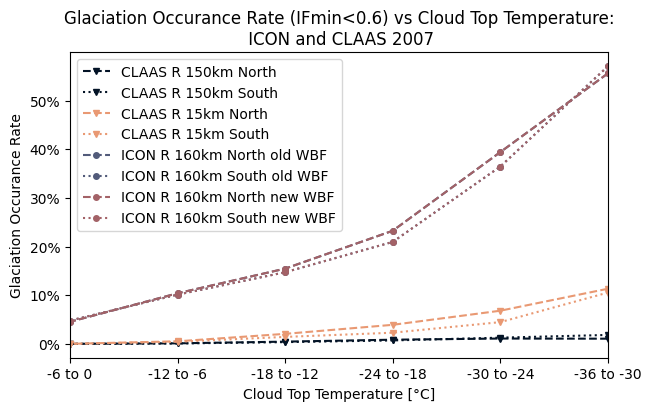

In [22]:
fig,ax = plt.subplots(1, 1, figsize=(6.4,  4), layout="constrained")
high_res_occ_rate = calculate_pole_temp_occurance_rate_glac_possible((clouds_high_res,None,None))
low_res_occ_rate = calculate_pole_temp_occurance_rate_glac_possible((clouds_low_res,None,None))
# model_occ_rate = calculate_pole_temp_occurance_rate((clouds_model_offline,None,None))
model_online_occ_rate = calculate_pole_temp_occurance_rate_glac_possible((clouds_model,None,None))
model_new_wbf_occ_rate = calculate_pole_temp_occurance_rate_glac_possible((clouds_model_new_wbf ,None,None))

ax.plot(low_res_occ_rate.columns,low_res_occ_rate.loc['North'],label='CLAAS R 150km North',color=colormap(0),linestyle='dashed',marker='v',markersize=4)
ax.plot(low_res_occ_rate.columns,low_res_occ_rate.loc['South'],label='CLAAS R 150km South',color=colormap(0),linestyle='dotted',marker='v',markersize=4)
ax.plot(high_res_occ_rate.columns,high_res_occ_rate.loc['North'],label='CLAAS R 15km North',color = colormap(3),linestyle='dashed',marker='v',markersize=4)
ax.plot(high_res_occ_rate.columns,high_res_occ_rate.loc['South'],label='CLAAS R 15km South',color = colormap(3),linestyle='dotted',marker='v',markersize=4)
# ax.plot(model_occ_rate.columns,model_occ_rate.loc['North'],label='ICON Old WBF R 160km North',color=colormap(2),linestyle='dashed',marker='v',markersize=4)
# ax.plot(model_occ_rate.columns,model_occ_rate.loc['South'],label='ICON Old WBF R 160km South',color=colormap(2),linestyle='dotted',marker='v',markersize=4)
ax.plot(model_online_occ_rate.columns,model_online_occ_rate.loc['North'],label='ICON R 160km North old WBF',color=colormap(4),linestyle='dashed',marker='o',markersize=4)
ax.plot(model_online_occ_rate.columns,model_online_occ_rate.loc['South'],label='ICON R 160km South old WBF',color=colormap(4),linestyle='dotted',marker='o',markersize=4)
ax.plot(model_new_wbf_occ_rate.columns,model_new_wbf_occ_rate.loc['North'],label='ICON R 160km North new WBF',color=colormap(2),linestyle='dashed',marker='o',markersize=4)
ax.plot(model_new_wbf_occ_rate.columns,model_new_wbf_occ_rate.loc['South'],label='ICON R 160km South new WBF',color=colormap(2),linestyle='dotted',marker='o',markersize=4)

ax.set_xlim(-36,-6)

ax.invert_xaxis()
vals = ax.get_yticks()
ax.set_yticklabels(['{:,.0%}'.format(x) for x in vals])
ax.set_ylabel('Glaciation Occurance Rate')
ax.legend(loc="upper left")
ax.set_xlabel('Cloud Top Temperature [°C]')
ax.set_xticks(np.arange(-36,-6+1,6),labels=[f"{i} to {i+6}" for i in range(-36,0,6)])
ax.set_title('Glaciation Occurance Rate (IFmin<0.6) vs Cloud Top Temperature:\n ICON and CLAAS 2007')
fig.savefig("/wolke_scratch/dnikolo/MSGI/figures/model_vs_CLAAS_occ_rate.png",dpi=300)

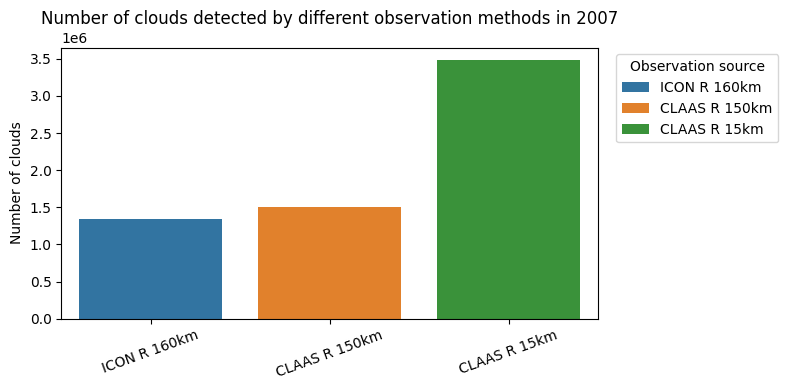

In [23]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Count rows in each dataframe
counts = pd.DataFrame({
    "Observation method": [
        "ICON R 160km",
        "CLAAS R 150km",
        "CLAAS R 15km",  
    ],
    "Num clouds (rows)": [
        len(clouds_model),
        len(clouds_low_res),
        len(clouds_high_res),
        
    ]
})

plt.figure(figsize=(8, 4))
ax = sns.barplot(
    data=counts,
    x="Observation method",
    y="Num clouds (rows)",
    hue="Observation method",      # makes a legend
    dodge=False
)

ax.set_xlabel("")
ax.set_ylabel("Number of clouds")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Observation source", bbox_to_anchor=(1.02, 1), loc="upper left")

# (optional) add value labels on bars
# for container in ax.containers:
#     ax.bar_label(container, fmt="%.0f", padding=3)
ax.set_title("Number of clouds detected by different observation methods in 2007")
plt.tight_layout()
plt.show()


In [24]:
import seaborn as sns

In [25]:
fig,ax = plt.subplots(1, 1, figsize=(6.4,  4), layout="constrained")
sns.histplot(clouds_model[clouds_model["avg_size[km]"]<1e5]["avg_size[km]"], log_scale=(False, True), bins=20,ax= ax,label="ICON R 160km" )
sns.histplot(clouds_high_res[clouds_high_res["avg_size[km]"]<1e5]["avg_size[km]"], log_scale=(False, True), bins=20,ax= ax,label="CLAAS R 15km")
sns.histplot(clouds_low_res[clouds_low_res["avg_size[km]"]<1e5]["avg_size[km]"], log_scale=(False, True), bins=20,ax= ax,label="CLAAS R 150km")
ax.set_title('Cloud top area distribution \n for different observation methods in 2007')
plt.legend()
ax.set_xlabel('Cloud top area [km^2]')

Text(0.5, 0, 'Cloud top area [km^2]')

Error in callback <function flush_figures at 0x7feebab2ccc0> (for post_execute):


KeyboardInterrupt: 

In [ ]:
(clouds_high_res["avg_size[km]"]<0.01e7).value_counts(normalize=True)

avg_size[km]
True     0.997858
False    0.002142
Name: proportion, dtype: float64

# Calculations

In [ ]:
(glac_model.Cloud_ID.value_counts()>1).value_counts(normalize=True)

count
False    0.927476
True     0.072524
Name: proportion, dtype: float64

In [ ]:
(glac_model_new_wbf.Cloud_ID.value_counts()>1).value_counts(normalize=True)

count
False    0.9605
True     0.0395
Name: proportion, dtype: float64

In [ ]:
(glac_low_res.Cloud_ID.value_counts()>1).value_counts(normalize=True)

count
False    0.996839
True     0.003161
Name: proportion, dtype: float64

In [ ]:
(glac_high_res.Cloud_ID.value_counts()>1).value_counts(normalize=True)

count
False    0.992448
True     0.007552
Name: proportion, dtype: float64

In [ ]:
from scipy.signal import savgol_filter

def noise_filter_4(row, w=4, order=2):
    IF_hist = np.array(row['ice_frac_hist'])
    return savgol_filter(IF_hist, w, order)

In [ ]:
se_sum=0
sample_count=0
for i, row in glac_high_res.iterrows():
    data = np.array(row['ice_frac_hist'])
    filt_data = noise_filter_4(row)
    # filt_data = savgol_filter(data, window_length=5, polyorder=2)
    first_estimate=0.1
    meas_idx = (data<1-first_estimate) & (data>first_estimate)
    se_sum += (np.square(data[meas_idx] - filt_data[meas_idx])).sum()
    sample_count+=len(data[meas_idx])
print(np.sqrt(se_sum/sample_count))

0.0651292202357399


In [ ]:
se_sum=0
sample_count=0
for i, row in glac_model.iterrows():
    data = np.array(row['ice_frac_hist'])
    filt_data = noise_filter_4(row)
    # filt_data = savgol_filter(data, window_length=5, polyorder=2)
    first_estimate=0.1
    meas_idx = (data<1-first_estimate) & (data>first_estimate)
    se_sum += (np.square(data[meas_idx] - filt_data[meas_idx])).sum()
    sample_count+=len(data[meas_idx])
print(np.sqrt(se_sum/sample_count))

0.09630264845824899


In [ ]:
se_sum=0
sample_count=0
for i, row in glac_model.iterrows():
    data = np.array(row['ice_frac_hist'])
    filt_data = noise_filter_4(row)
    # filt_data = savgol_filter(data, window_length=5, polyorder=2)
    first_estimate=0.1
    meas_idx = (data<1-first_estimate) & (data>first_estimate)
    se_sum += (np.square(data[meas_idx] - filt_data[meas_idx])).sum()
    sample_count+=len(data[meas_idx])
print(np.sqrt(se_sum/sample_count))

In [ ]:
(glac_low_res["Time [m]"]==15).value_counts()

Time [m]
False    1396
True       85
Name: count, dtype: int64

## Deprecated

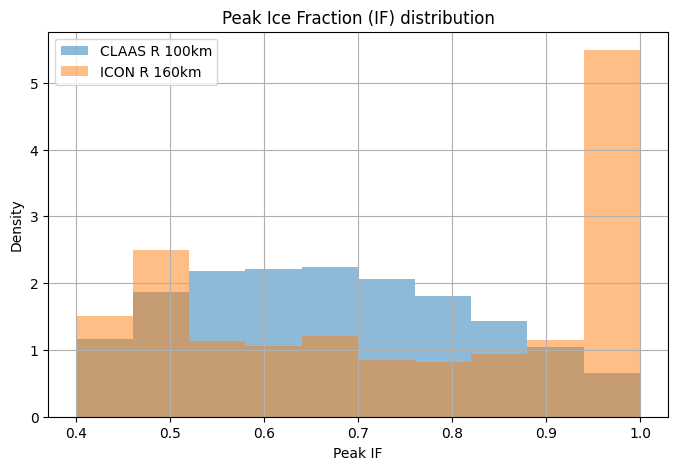

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
glac_low_res["Peak IF"].hist( alpha=0.5, density=True,label="CLAAS R 150km")
# glac_model_offline["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON Old WBF R 160km")
glac_model["Peak IF"].hist( alpha=0.5, density=True,label="ICON R 160km")
plt.title("Peak Ice Fraction (IF) distribution")
plt.xlabel("Peak IF")
plt.ylabel("Density")
plt.legend()

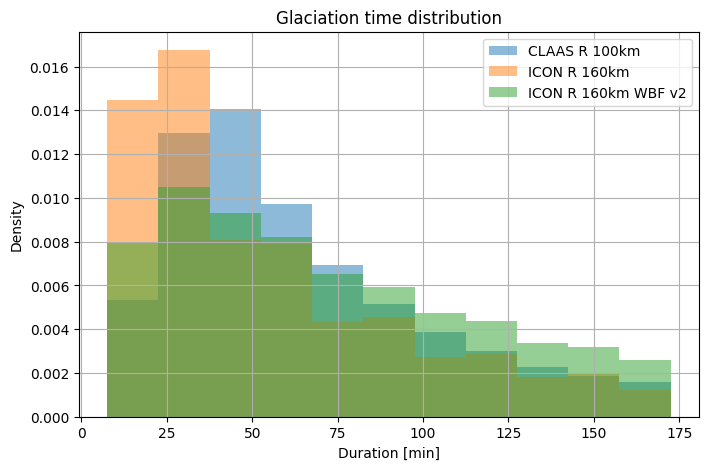

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
# glac_low_res["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="CLAAS R 150km")
# glac_model_offline["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON Old WBF R 160km")
glac_high_res["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="CLAAS R 150km")
glac_model["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON R 160km")
glac_model_new_wbf["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON R 160km WBF v2")
# glac_model["Time [m]"].hist( alpha=0.5, density=True,label="ICON R 160km")
plt.title("Glaciation time distribution")
plt.xlabel("Duration [min]")
plt.ylabel("Density")
plt.legend()